# 01 · Corpus: from PDFs to clean text

**DNE A2 — GraphRAG vs plain RAG on the World Tennis Coaching & Sport Science Review.**

This notebook checks the raw corpus, extracts clean text from each article PDF (code in `dne/extract.py`, tested in `tests/test_extract.py`), and measures the corpus in tokens. The token count drives the cost and runtime estimates for building the graph on Kaggle and for the Claude judge.

Outputs: `data/processed/text/<aid>.txt` (one file per usable article) and `data/processed/articles.csv`.

In [1]:
import sys, subprocess
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from dne.paths import ROOT, PROCESSED, FIGURES, TEXT_DIR

import pandas as pd
import matplotlib.pyplot as plt

print("repo:", ROOT)

repo: /Users/tf/dev/dne_graphrag


## 1. Raw corpus check

587 articles harvested 15–16/10/2026: one metadata file and one English PDF each. Nothing in `data/raw/` is ever edited.

In [2]:
r = subprocess.run([sys.executable, str(ROOT / "tools/check_raw.py")], capture_output=True, text=True)
print(r.stdout, r.stderr)
r.check_returncode()  # stops here without data/raw/ (see README: the raw PDFs are not shipped)

587 meta, 795 pdf, 0 bad headers
issues.json: 52 issues, 587 articles



## 2. Extraction

For each article: read the PDF text page by page, drop running headers/footers (lines repeated on half the pages or more), bare page numbers and the reference list, re-join hyphenated words, and prepend a header line block (title, authors, year, issue, article id) so every chunk can be traced back to its article.

Articles are flagged and left out when the text is under 500 characters (`too_short`) or the metadata language isn't English (`not_english`).

In [3]:
r = subprocess.run([sys.executable, str(ROOT / "tools/extract_all.py")], capture_output=True, text=True)
print(r.stdout, r.stderr)
r.check_returncode()
arts = pd.read_csv(PROCESSED / "articles.csv")
arts["status"].value_counts()

{'ok': 541, 'no_pdf': 43, 'too_short': 3} tokens(ok)=1,636,287



status
ok           541
no_pdf        43
too_short      3
Name: count, dtype: int64

## 3. Corpus size

usable articles: 541 of 587
tokens (cl100k): total 1,636,287 · median 2,479 · max 10,216


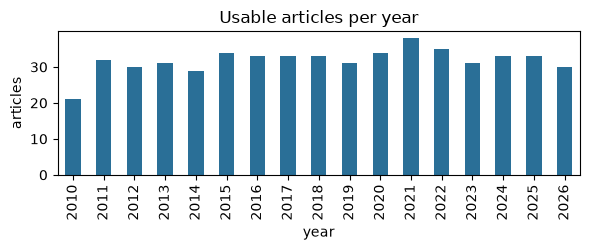

In [4]:
ok = arts[arts.status == "ok"]
print(f"usable articles: {len(ok)} of {len(arts)}")
print(f"tokens (cl100k): total {ok.n_tokens.sum():,} · median {ok.n_tokens.median():,.0f} · max {ok.n_tokens.max():,}")

FIGURES.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(6, 2.6))
ok.groupby("year").size().plot.bar(ax=ax, color="#2a6f97")
ax.set_xlabel("year"); ax.set_ylabel("articles"); ax.set_title("Usable articles per year")
fig.tight_layout(); fig.savefig(FIGURES / "corpus_per_year.pdf")
plt.show()

## 4. Cost and runtime estimates (made before the pilot)

GraphRAG splits the text into chunks (default ~1,200 tokens) and asks the LLM to extract entities and relations from each one, with a long instruction prompt around every chunk. The figures below are the rough projections made before the pilot runs, kept as a record; the measured costs are in the report (compute and indexing-cost tables).

Assumptions (stated so they can be checked): ~2,000 prompt tokens of instructions per chunk, ~600 output tokens per chunk, one extra "gleaning" pass, plus ~15 % on top for community reports. Judge: 60 questions × 3 system pairs × 2 orders, ~4,000 input + ~500 output tokens per call, plus 20 lookup questions × 3 systems correctness checks.

In [5]:
from dne.spend import cost_usd

CHUNK, PROMPT_OVERHEAD, OUT_PER_CHUNK, PASSES, REPORTS = 1200, 2000, 600, 2, 1.15
chunks = int(ok.n_tokens.sum() / CHUNK) + len(ok)
idx_in = chunks * (CHUNK + PROMPT_OVERHEAD) * PASSES * REPORTS
idx_out = chunks * OUT_PER_CHUNK * PASSES * REPORTS
print(f"chunks ≈ {chunks:,} → indexing ≈ {idx_in/1e6:.1f}M prompt + {idx_out/1e6:.1f}M output tokens")
print(f"   (if done on Claude instead: Haiku 5.5 ${cost_usd('claude-haiku-5-5', idx_in, idx_out):.0f}, "
      f"Sonnet 5.5 ${cost_usd('claude-sonnet-5-5', idx_in, idx_out):.0f})")

judge_calls = 60 * 3 * 2 + 20 * 3
j_in, j_out = judge_calls * 4000, judge_calls * 500
print(f"judge: {judge_calls} calls ≈ ${cost_usd('claude-opus-5-5', j_in, j_out):.2f} on Opus 5.5 (cap $20)")

chunks ≈ 1,904 → indexing ≈ 14.0M prompt + 2.6M output tokens
   (if done on Claude instead: Haiku 5.5 $3, Sonnet 5.5 $54)
judge: 420 calls ≈ $10.92 on Opus 5.5 (cap $20)
